
# 21 — Why geometric context sampling is enough under power-law decay

Notebooks 12--15 established empirically that logarithmically spaced context lengths can
retain the downstream information of dense context-length probing (CLP). Notebook 19
showed that the dense curve is extremely low-dimensional. Notebook 20 then found a
response-level explanation:

\[
\bar m(d)
=
\mathbb E_x[L_{d-1}(x)-L_d(x)]
\approx
a\,d^{-\alpha},
\]

with approximately

\[
\alpha_{\mathrm{GPT2}}\approx1.35,
\qquad
\alpha_{\mathrm{Qwen}}\approx1.43,
\]

over \(d=9,\ldots,256\).

This notebook asks whether that empirical scaling law is mathematically sufficient to
explain why **geometric \(O(\log N)\) sampling** can approximate an \(O(N)\) dense CLP
curve.

The goal is deliberately modest:

> derive an approximation bound for the idealized integrated power-law response, and
> test how well its predictions describe the actual dense curves.

This is a theory of **curve reconstruction / measurement resolution**. It does not by
itself prove downstream attribution non-inferiority; notebook 15 supplies that empirical
task-level result.



## 1. General log-grid interpolation lemma

Let the endpoint-normalized CLP shape be

\[
S(k)=L_k-L_N,
\qquad
k\in[k_0,N].
\]

Introduce log-context coordinate

\[
x=\log k,
\qquad
G(x)=S(e^x).
\]

Suppose \(G\) is twice differentiable and

\[
|G''(x)|\le B
\]

throughout the interval. Let \(\widetilde G\) be the piecewise-linear interpolant on a
uniform log-grid with maximum spacing \(h\). The standard linear-interpolation remainder
gives, interval by interval,

\[
\boxed{
\|G-\widetilde G\|_\infty
\le
\frac{B h^2}{8}.
}
\]

A uniform grid in \(x=\log k\) is exactly a **geometric grid in context length**:

\[
k_i=k_0 r^i,
\qquad
h=\log r.
\]

To cover \([k_0,N]\),

\[
M
=
1+\left\lceil
\frac{\log(N/k_0)}{h}
\right\rceil.
\]

Therefore, for fixed curvature scale \(B\) and fixed target absolute error
\(\varepsilon\),

\[
h\le\sqrt{\frac{8\varepsilon}{B}}
\]

is sufficient, and hence

\[
\boxed{
M
=
O\!\left(
\frac{\log(N/k_0)}{\sqrt{\varepsilon}}
\right).
}
\]

For fixed error tolerance, this is \(O(\log N)\) context measurements.

The statement above is generic: the special power-law form below lets us eliminate the
unknown amplitude and obtain a dimensionless error bound.



## 2. Specialization to an integrated power-law marginal response

Assume the continuous idealization

\[
m(d)=a d^{-\alpha},
\qquad
\alpha>1.
\]

Write

\[
\beta=\alpha-1>0.
\]

Then

\[
S(k)
\approx
\int_k^N a d^{-\alpha}\,dd
=
\frac{a}{\beta}
\left(
k^{-\beta}-N^{-\beta}
\right).
\]

In log coordinate \(x=\log k\),

\[
G(x)
=
\frac{a}{\beta}
\left(
e^{-\beta x}-N^{-\beta}
\right),
\]

so

\[
G''(x)
=
a\beta e^{-\beta x}.
\]

The largest curvature occurs at \(k=k_0\):

\[
B
=
|a|\beta k_0^{-\beta}.
\]

Normalize the interpolation error by the total short-to-long shape amplitude

\[
|S(k_0)|
=
\frac{|a|}{\beta}
\left(
k_0^{-\beta}-N^{-\beta}
\right).
\]

The amplitude \(a\) cancels, giving

\[
\boxed{
\frac{
\|S-\widetilde S\|_\infty
}{
|S(k_0)|
}
\le
\frac{
\beta^2 h^2
}{
8\left[1-(k_0/N)^\beta\right]
}.
}
\]

For a geometric ratio \(r\),

\[
h=\log r,
\]

so

\[
\boxed{
E_{\mathrm{rel}}
\le
\frac{
(\alpha-1)^2(\log r)^2
}{
8\left[1-(k_0/N)^{\alpha-1}\right]
}.
}
\]

The number of samples is

\[
M
\approx
1+\frac{\log(N/k_0)}{\log r}.
\]

Equivalently, solving the bound for a target normalized error \(\varepsilon\),

\[
\boxed{
M
\ge
1+
\frac{
(\alpha-1)\log(N/k_0)
}{
\sqrt{
8\varepsilon
\left[
1-(k_0/N)^{\alpha-1}
\right]
}
}.
}
\]

For fixed \(\alpha>1\), \(k_0\), and \(\varepsilon\), the required measurement count is
therefore \(O(\log N)\).

### Harmonic limit

As \(\alpha\to1\), or equivalently \(\beta\to0\),

\[
S(k)
\to
a\log\frac Nk.
\]

This is **exactly linear in \(\log k\)**. Consequently, log-linear interpolation on any
geometric grid is exact in the ideal harmonic limit.

Thus an exponent near one provides a direct mathematical reason that coarse geometric
sampling can approximate dense CLP extremely well.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

QWEN_PATH = RESULTS / "cifka_dense_clp_qwen06b.parquet"
GPT2_PATH = RESULTS / "cifka_dense_clp_gpt2.parquet"

assert QWEN_PATH.exists(), QWEN_PATH
assert GPT2_PATH.exists(), GPT2_PATH

MIN_K, MAX_K = 8, 256
K_ALL = np.arange(MIN_K, MAX_K + 1)
L_COLS = [f"L_{k}" for k in K_ALL]
DISTANCES = np.arange(MIN_K + 1, MAX_K + 1)

print("ROOT:", ROOT)
print("Dense coordinates:", len(L_COLS))


ROOT: ..
Dense coordinates: 249


In [2]:

def prepare(path, scorer):
    df = pd.read_parquet(path).copy()
    df = df.dropna(subset=L_COLS)

    pairs = df.groupby("pair_id")["generator"].agg(["size", "nunique"])
    ok = pairs.index[(pairs["size"] == 2) & (pairs["nunique"] == 2)]
    df = df[df["pair_id"].isin(ok)].copy()

    df["scorer"] = scorer
    return df


qwen = prepare(QWEN_PATH, "Qwen3-0.6B")
gpt2 = prepare(GPT2_PATH, "GPT-2")

for scorer, df in [("Qwen3-0.6B", qwen), ("GPT-2", gpt2)]:
    print(scorer, "pairs", df["pair_id"].nunique(), "docs", len(df))
    display(df.groupby(["domain", "generator"]).size())


Qwen3-0.6B pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

GPT-2 pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64


## 3. Re-estimate the direct marginal exponent self-contained

To keep this notebook independent of notebook 20's saved summary, re-estimate

\[
\bar m(d)
=
\mathbb E_x[L_{d-1}-L_d]
\]

using the same 16 logarithmic distance bins.

This estimate is used only to parameterize the theoretical prediction below.


In [3]:

N_BINS = 16

def dense_and_marginal(df):
    L = df[L_COLS].to_numpy(dtype=float)
    M = L[:, :-1] - L[:, 1:]
    return L, M


def binned_direct_alpha(M, n_bins=N_BINS):
    edges = np.geomspace(
        DISTANCES.min(),
        DISTANCES.max() + 1,
        n_bins + 1,
    )

    mean_m = M.mean(axis=0)
    rows = []

    for i in range(n_bins):
        mask = (
            (DISTANCES >= edges[i]) &
            (DISTANCES < edges[i + 1])
        )

        if not mask.any():
            continue

        d_mid = np.exp(np.mean(np.log(DISTANCES[mask])))
        y = mean_m[mask].mean()

        rows.append({
            "bin": i,
            "d_mid": d_mid,
            "mean_marginal": y,
            "n_distances": int(mask.sum()),
        })

    b = pd.DataFrame(rows)
    q = b[b["mean_marginal"] > 0].copy()

    x = np.log(q["d_mid"].to_numpy())
    y = np.log(q["mean_marginal"].to_numpy())

    slope, intercept = np.polyfit(x, y, 1)
    pred = intercept + slope * x

    ss_res = np.square(y - pred).sum()
    ss_tot = np.square(y - y.mean()).sum()

    return {
        "alpha": -slope,
        "intercept": intercept,
        "r2": 1.0 - ss_res / ss_tot,
        "bins": b,
    }


matrix_cache = {}
alpha_rows = []

for scorer, df in [("Qwen3-0.6B", qwen), ("GPT-2", gpt2)]:
    L, M = dense_and_marginal(df)
    fit = binned_direct_alpha(M)

    matrix_cache[scorer] = {
        "df": df,
        "L": L,
        "M": M,
        "alpha": fit["alpha"],
    }

    alpha_rows.append({
        "scorer": scorer,
        "alpha_direct": fit["alpha"],
        "loglog_r2": fit["r2"],
    })

alpha_summary = pd.DataFrame(alpha_rows)
display(alpha_summary)


,scorer,alpha_direct,loglog_r2
0,Qwen3-0.6B,1.424527,0.997558
1,GPT-2,1.351169,0.992791



## 4. What does the observed exponent predict for powers-of-two sampling?

For the SL6 grid

\[
8,16,32,64,128,256,
\]

the geometric ratio is

\[
r=2,
\qquad
h=\log2.
\]

Plug the empirically estimated \(\alpha\) into the normalized interpolation bound.


In [4]:

def normalized_powerlaw_bound(alpha, k0=MIN_K, N=MAX_K, ratio=2.0):
    beta = alpha - 1.0
    h = np.log(ratio)

    return (
        beta ** 2 * h ** 2
        /
        (
            8.0 *
            (1.0 - (k0 / N) ** beta)
        )
    )


bound_rows = []

for _, row in alpha_summary.iterrows():
    alpha = float(row["alpha_direct"])
    beta = alpha - 1.0

    bound_rows.append({
        "scorer": row["scorer"],
        "alpha": alpha,
        "beta": beta,
        "ratio": 2.0,
        "n_measurements": 6,
        "normalized_sup_error_bound":
            normalized_powerlaw_bound(alpha),
    })

doubling_bound = pd.DataFrame(bound_rows)
display(doubling_bound)


,scorer,alpha,beta,ratio,n_measurements,normalized_sup_error_bound
0,Qwen3-0.6B,1.424527,0.424527,2.0,6,0.014050
1,GPT-2,1.351169,0.351169,2.0,6,0.010522



The bound above is conservative and applies to the **idealized continuous integrated
power-law curve**. It is not an empirical confidence interval and does not cover
document-specific residual variation.

For additional intuition, compute the exact interpolation error of that idealized
continuous curve under the same sampled grid. This is not a proof; it shows how loose
the generic curvature bound is.


In [5]:

def log_grid(m, k0=MIN_K, N=MAX_K):
    if m == 1:
        return [N]

    ideal = np.geomspace(k0, N, m)
    chosen = []
    unused = set(range(k0, N + 1))

    for z in ideal:
        k = min(
            unused,
            key=lambda q: (
                abs(np.log(q) - np.log(z)),
                q,
            ),
        )
        chosen.append(k)
        unused.remove(k)

    chosen = sorted(chosen)

    if chosen[0] != k0:
        chosen[0] = k0
    if chosen[-1] != N:
        chosen[-1] = N

    while len(set(chosen)) < m:
        used = set(chosen)
        candidates = [
            q for q in range(k0, N + 1)
            if q not in used
        ]

        q = min(
            candidates,
            key=lambda q: min(
                abs(np.log(q) - np.log(z))
                for z in ideal
            ),
        )

        chosen.append(q)
        chosen = sorted(chosen)

    assert len(chosen) == m
    assert len(set(chosen)) == m

    return chosen


def ideal_power_shape(k, alpha, N=MAX_K):
    beta = alpha - 1.0
    k = np.asarray(k, dtype=float)

    return (
        k ** (-beta) - N ** (-beta)
    ) / beta


def exact_ideal_log_interp_error(alpha, grid):
    x = np.linspace(
        np.log(MIN_K),
        np.log(MAX_K),
        100_000,
    )

    k = np.exp(x)
    true = ideal_power_shape(k, alpha)

    grid = np.asarray(grid, dtype=float)
    pred = np.interp(
        x,
        np.log(grid),
        ideal_power_shape(grid, alpha),
    )

    return (
        np.max(np.abs(pred - true))
        /
        abs(ideal_power_shape(MIN_K, alpha))
    )


for _, row in alpha_summary.iterrows():
    scorer = row["scorer"]
    alpha = float(row["alpha_direct"])
    grid = log_grid(6)

    print(
        scorer,
        "| alpha =", round(alpha, 4),
        "| grid =", grid,
        "| theoretical bound =",
        round(normalized_powerlaw_bound(alpha), 5),
        "| exact ideal error =",
        round(exact_ideal_log_interp_error(alpha, grid), 5),
    )


Qwen3-0.6B | alpha = 1.4245 | grid = [8, 16, 32, 64, 128, 256] | theoretical bound = 0.01405 | exact ideal error = 0.01216
GPT-2 | alpha = 1.3512 | grid = [8, 16, 32, 64, 128, 256] | theoretical bound = 0.01052 | exact ideal error = 0.00933



## 5. Empirical geometric-grid reconstruction

We now leave the idealized power-law model and reconstruct each observed dense curve.

For each document define

\[
S_x(k)=L_k(x)-L_{256}(x),
\qquad
k=8,\ldots,256.
\]

For

\[
M\in\{2,3,4,6,8,16,32\},
\]

sample \(M\) approximately uniformly spaced points in \(\log k\), interpolate the rest,
and compare against the observed dense shape.

Two interpolation coordinates are compared:

- `log_k`: linear interpolation in \(\log k\);
- `linear_k`: ordinary interpolation in \(k\).

Per-document reconstruction error is measured by

\[
\mathrm{NRMSE}
=
\sqrt{
\frac{
\sum_k(S_x(k)-\widehat S_x(k))^2
}{
\sum_kS_x(k)^2
}
}
\]

and by a maximum absolute error normalized by the short-to-long shape amplitude

\[
E_{\max}
=
\frac{
\max_k |S_x(k)-\widehat S_x(k)|
}{
|S_x(8)|
}.
\]


In [6]:

M_GRID = [2, 3, 4, 6, 8, 16, 32]

reconstruction_rows = []

for scorer, pack in matrix_cache.items():
    L = pack["L"]
    S = L - L[:, [-1]]

    for m in M_GRID:
        grid = log_grid(m)
        grid_idx = np.array([k - MIN_K for k in grid])

        for method in ["log_k", "linear_k"]:
            if method == "log_k":
                x_all = np.log(K_ALL)
                x_grid = np.log(np.asarray(grid))
            else:
                x_all = K_ALL.astype(float)
                x_grid = np.asarray(grid, dtype=float)

            for i in range(len(S)):
                true = S[i]
                sampled = true[grid_idx]

                pred = np.interp(
                    x_all,
                    x_grid,
                    sampled,
                )

                err = true - pred

                denom_rms = np.sqrt(np.mean(true ** 2))
                denom_amp = max(abs(true[0]), 1e-12)

                reconstruction_rows.append({
                    "scorer": scorer,
                    "doc_index": i,
                    "m": m,
                    "grid": ",".join(map(str, grid)),
                    "method": method,
                    "nrmse":
                        np.sqrt(np.mean(err ** 2)) / max(denom_rms, 1e-12),
                    "max_abs_normalized":
                        np.max(np.abs(err)) / denom_amp,
                })

recon_docs = pd.DataFrame(reconstruction_rows)

recon_summary = (
    recon_docs
    .groupby(["scorer", "m", "method"])
    .agg(
        median_nrmse=("nrmse", "median"),
        mean_nrmse=("nrmse", "mean"),
        p90_nrmse=("nrmse", lambda x: np.quantile(x, 0.90)),
        median_max_abs=("max_abs_normalized", "median"),
        mean_max_abs=("max_abs_normalized", "mean"),
        p90_max_abs=("max_abs_normalized", lambda x: np.quantile(x, 0.90)),
    )
    .reset_index()
)

recon_docs.to_csv(
    RESULTS / "clp_geometric_sampling_reconstruction_docs.csv",
    index=False,
)
recon_summary.to_csv(
    RESULTS / "clp_geometric_sampling_reconstruction_summary.csv",
    index=False,
)

display(recon_summary)


,scorer,m,method,median_nrmse,mean_nrmse,p90_nrmse,median_max_abs,mean_max_abs,p90_max_abs
0,GPT-2,2,linear_k,1.349969,1.393668,1.970864,0.564261,0.564347,0.683910
1,GPT-2,2,log_k,0.374753,0.435287,0.769043,0.220716,0.228468,0.333091
2,GPT-2,3,linear_k,0.393774,0.403454,0.578511,0.240487,0.247390,0.327791
3,GPT-2,3,log_k,0.198670,0.217872,0.339437,0.143160,0.150764,0.219634
4,GPT-2,4,linear_k,0.196792,0.204008,0.298961,0.150953,0.155710,0.215698
5,GPT-2,4,log_k,0.141968,0.153789,0.224900,0.113214,0.122206,0.180958
6,GPT-2,6,linear_k,0.112172,0.123264,0.181747,0.099450,0.107761,0.159755
7,GPT-2,6,log_k,0.105252,0.114435,0.165351,0.091041,0.100198,0.152576
8,GPT-2,8,linear_k,0.094575,0.100516,0.140092,0.086286,0.093860,0.140239
9,GPT-2,8,log_k,0.088499,0.095821,0.131996,0.083440,0.090072,0.132788


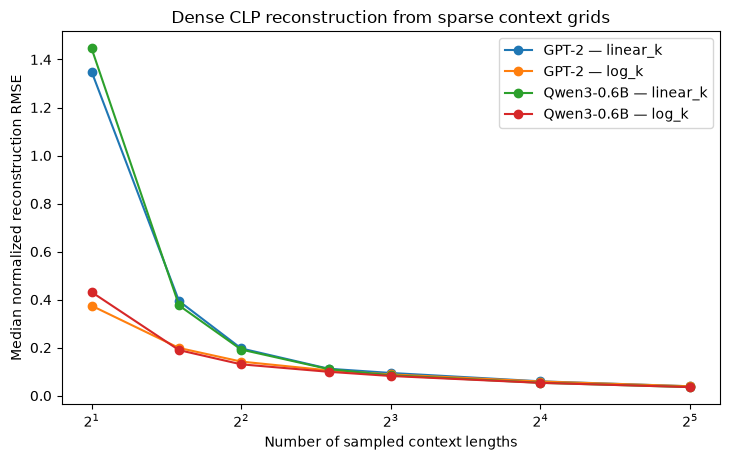

In [7]:

fig, ax = plt.subplots(figsize=(7.4, 4.7))

for (scorer, method), g in recon_summary.groupby(
    ["scorer", "method"]
):
    ax.plot(
        g["m"],
        g["median_nrmse"],
        marker="o",
        label=f"{scorer} — {method}",
    )

ax.set_xscale("log", base=2)
ax.set_xlabel("Number of sampled context lengths")
ax.set_ylabel("Median normalized reconstruction RMSE")
ax.set_title("Dense CLP reconstruction from sparse context grids")
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_geometric_sampling_reconstruction.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "clp_geometric_sampling_reconstruction.pdf",
    bbox_inches="tight",
)
plt.show()



## 6. Compare observed mean-shape error with the theoretical power-law prediction

The theorem applies to the idealized shared smooth response, not to every noisy
document-level curve. The closest empirical analogue is therefore the **mean CLP shape**
for each scorer.

For each \(M\), compare:

1. the generic curvature upper bound under the fitted power-law exponent;
2. the exact idealized power-law interpolation error;
3. the actual mean-shape interpolation error.

The first is a mathematical guarantee under the model, the second is the model's actual
error, and the third measures model mismatch plus interpolation error in the data.


In [8]:

theory_rows = []

for scorer, pack in matrix_cache.items():
    L = pack["L"]
    S = L - L[:, [-1]]
    mean_shape = S.mean(axis=0)

    alpha = float(pack["alpha"])
    beta = alpha - 1.0

    for m in M_GRID:
        grid = log_grid(m)
        grid_idx = np.array([k - MIN_K for k in grid])

        x_grid = np.log(np.asarray(grid, dtype=float))
        x_all = np.log(K_ALL.astype(float))

        # Actual maximum spacing matters after integer rounding.
        h_max = np.max(np.diff(x_grid))

        bound = (
            beta ** 2 * h_max ** 2
            /
            (
                8.0 *
                (1.0 - (MIN_K / MAX_K) ** beta)
            )
        )

        ideal_err = exact_ideal_log_interp_error(alpha, grid)

        pred_mean = np.interp(
            x_all,
            x_grid,
            mean_shape[grid_idx],
        )

        observed_mean_err = (
            np.max(np.abs(mean_shape - pred_mean))
            /
            abs(mean_shape[0])
        )

        theory_rows.append({
            "scorer": scorer,
            "m": m,
            "grid": ",".join(map(str, grid)),
            "alpha": alpha,
            "h_max": h_max,
            "theoretical_bound": bound,
            "ideal_powerlaw_error": ideal_err,
            "observed_mean_shape_error": observed_mean_err,
        })

theory_validation = pd.DataFrame(theory_rows)

theory_validation.to_csv(
    RESULTS / "clp_geometric_sampling_theory_validation.csv",
    index=False,
)

display(theory_validation)


,scorer,m,grid,alpha,h_max,theoretical_bound,ideal_powerlaw_error,observed_mean_shape_error
0,Qwen3-0.6B,2,"8,256",1.424527,3.465736,0.351245,0.178636,0.174789
1,Qwen3-0.6B,3,"8,45,256",1.424527,1.738515,0.088384,0.061371,0.074190
2,Qwen3-0.6B,4,"8,25,81,256",1.424527,1.175573,0.040413,0.030004,0.040723
3,Qwen3-0.6B,6,"8,16,32,64,128,256",1.424527,0.693147,0.014050,0.012157,0.016729
4,Qwen3-0.6B,8,"8,13,22,35,58,95,156,256",1.424527,0.526093,0.008094,0.006225,0.009241
5,Qwen3-0.6B,16,"8,10,13,16,20,25,32,40,51,64,81,102,128,161,20...",1.424527,0.262364,0.002013,0.001732,0.003850
6,Qwen3-0.6B,32,"8,9,10,11,13,14,16,18,20,22,24,27,31,34,38,43,...",1.424527,0.167054,0.000816,0.000688,0.002631
7,GPT-2,2,"8,256",1.351169,3.465736,0.263041,0.149102,0.127147
8,GPT-2,3,"8,45,256",1.351169,1.738515,0.066189,0.048736,0.056187
9,GPT-2,4,"8,25,81,256",1.351169,1.175573,0.030264,0.023380,0.034096


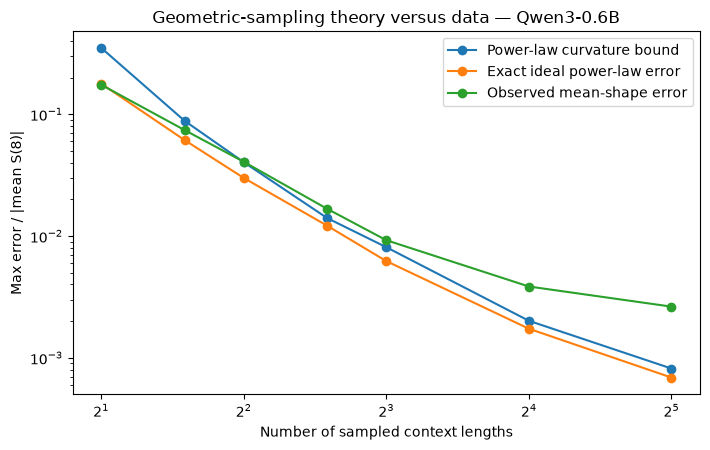

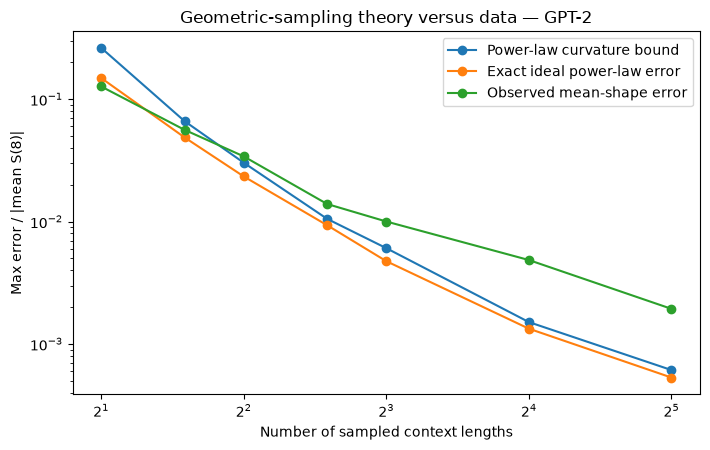

In [9]:

for scorer in ["Qwen3-0.6B", "GPT-2"]:
    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    s = theory_validation[
        theory_validation["scorer"] == scorer
    ]

    ax.plot(
        s["m"],
        s["theoretical_bound"],
        marker="o",
        label="Power-law curvature bound",
    )
    ax.plot(
        s["m"],
        s["ideal_powerlaw_error"],
        marker="o",
        label="Exact ideal power-law error",
    )
    ax.plot(
        s["m"],
        s["observed_mean_shape_error"],
        marker="o",
        label="Observed mean-shape error",
    )

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Number of sampled context lengths")
    ax.set_ylabel("Max error / |mean S(8)|")
    ax.set_title(f"Geometric-sampling theory versus data — {scorer}")
    ax.legend()
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(
        FIGURES / f"clp_geometric_sampling_theory_{stem}.png",
        dpi=220,
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"clp_geometric_sampling_theory_{stem}.pdf",
        bbox_inches="tight",
    )
    plt.show()



## 7. Sample-complexity prediction

For a normalized error tolerance \(\varepsilon\), the power-law curvature bound gives

\[
M
\ge
1+
\frac{
\beta\log(N/k_0)
}{
\sqrt{
8\varepsilon
\left[
1-(k_0/N)^\beta
\right]
}
},
\qquad
\beta=\alpha-1.
\]

Evaluate this prediction for several error tolerances.


In [10]:

EPS_GRID = [0.005, 0.01, 0.02, 0.05]

sample_complexity_rows = []

for _, row in alpha_summary.iterrows():
    scorer = row["scorer"]
    alpha = float(row["alpha_direct"])
    beta = alpha - 1.0

    for eps in EPS_GRID:
        required = (
            1.0
            +
            beta * np.log(MAX_K / MIN_K)
            /
            np.sqrt(
                8.0 * eps *
                (
                    1.0 -
                    (MIN_K / MAX_K) ** beta
                )
            )
        )

        sample_complexity_rows.append({
            "scorer": scorer,
            "alpha": alpha,
            "target_normalized_sup_error": eps,
            "continuous_required_M": required,
            "integer_sufficient_M": int(np.ceil(required)),
        })

sample_complexity = pd.DataFrame(sample_complexity_rows)
sample_complexity.to_csv(
    RESULTS / "clp_geometric_sampling_sample_complexity.csv",
    index=False,
)

display(sample_complexity)


,scorer,alpha,target_normalized_sup_error,continuous_required_M,integer_sufficient_M
0,Qwen3-0.6B,1.424527,0.005,9.381465,10
1,Qwen3-0.6B,1.424527,0.010,6.926590,7
2,Qwen3-0.6B,1.424527,0.020,5.190732,6
3,Qwen3-0.6B,1.424527,0.050,3.650452,4
4,GPT-2,1.351169,0.005,8.253147,9
5,GPT-2,1.351169,0.010,6.128749,7
6,GPT-2,1.351169,0.020,4.626573,5
7,GPT-2,1.351169,0.050,3.293646,4



## Interpretation

The theory and the empirical task-level result play different roles.

### What is established mathematically

If endpoint-normalized CLP follows an integrated power law

\[
S(k)
=
\frac{a}{\alpha-1}
\left(
k^{1-\alpha}-N^{1-\alpha}
\right),
\]

then piecewise-linear interpolation in \(\log k\) on a geometric grid has normalized
error bounded by

\[
O((\log r)^2),
\]

while the number of measurements required to cover \([k_0,N]\) is

\[
O(\log_r(N/k_0)).
\]

For a fixed target error tolerance, this yields \(O(\log N)\) measurement complexity.

### Why the observed exponent is favorable

The empirically fitted exponents are only moderately above one. In the exact
\(\alpha=1\) limit, the integrated response is

\[
S(k)=a\log(N/k),
\]

which is exactly linear in log-context and therefore exactly reconstructible from any
geometric grid by log-linear interpolation.

Thus the empirical regime \(\alpha\approx1.3\)--\(1.4\) naturally predicts small
curvature in log-context coordinates.

### What remains empirical

Real document-level marginal responses are noisy and high-dimensional, so the
power-law bound is not a universal guarantee for every document. Notebook 20 showed
that cumulative integration suppresses much of that local variation.

Most importantly, curve reconstruction is not identical to retaining a downstream
classification statistic. The formal \(O(\log N)\)-versus-\(O(N)\) non-inferiority
result remains empirical and is provided by notebooks 14--15.

The combined argument is therefore:

\[
\boxed{
\text{power-law marginal decay}
\Longrightarrow
\text{smooth low-curvature CLP in }\log k
\Longrightarrow
\text{geometric grids have }O(\log N)\text{ reconstruction complexity}
}
\]

together with the independent empirical observation that this sparse resolution is
sufficient for the tested source-attribution task.



## Conclusion template

Fill after running the empirical validation.

- **Observed exponents:** [GPT-2, Qwen]
- **SL6 theoretical normalized bound:** [values]
- **SL6 exact ideal power-law error:** [values]
- **SL6 observed mean-shape error:** [values]
- **SL6 document-level median NRMSE:** [values]
- **Log-space versus linear-space interpolation:** [comparison]
- **Theory conclusion:** [Does the observed power law quantitatively explain why a
  powers-of-two grid is adequate?]
- **Scope:** This explains measurement-resolution compressibility, not scorer-internal
  mechanism and not task non-inferiority by theorem alone.
